# BunkerMini Drive Test

Replay saved drive-simulation artifacts without starting ROS or rerunning the motion test.

In [1]:
from pathlib import Path
import csv, hashlib, html, json
from IPython.display import Image, Markdown, display
name = 'BunkerMini_drive_test'
locations = [candidate for parent in [Path.cwd(), *Path.cwd().parents]
             for candidate in [parent, parent/name,
                 parent/'Code'/'10.27_ROS_simulation'/name]]
root = next(p for p in locations if p.name == name and (p/'result').is_dir())
def read(path):
    return json.loads(path.read_text(encoding='utf-8'))
def show(headers, rows):
    display(Markdown('\n'.join(['| '+' | '.join(headers)+' |',
        '|'+'---|'*len(headers)] +
        ['| '+' | '.join(str(v) for v in row)+' |' for row in rows])))

## 1. Configuration and run record

In [2]:
run = root/'result'/'run_20261027T222926_983017Z'
manifest = read(run/'manifest.json')
metrics = read(run/'metrics.json')
verification = read(run/'verification.json')
show(['Configuration', 'Value'], [[key, manifest[key]] for key in
    ['status', 'started_utc', 'mode', 'gui', 'ros_distro', 'gazebo_version',
     'ros_domain_id', 'model_commit', 'mesh_sha256']])
show(['Drive parameter', 'Value'], list(manifest['drive_config'].items()))

| Configuration | Value |
|---|---|
| status | passed |
| started_utc | 2026-10-27T22:29:26.983017+00:00 |
| mode | simulation |
| gui | False |
| ros_distro | jazzy |
| gazebo_version | 8.11.0 |
| ros_domain_id | 71 |
| model_commit | 27633a956c845903ee630538afeb17fe70afdd84 |
| mesh_sha256 | af09e88d1b29b3a436083443f6030529a8e95b07a91ed23975e58799cf250f52 |

| Drive parameter | Value |
|---|---|
| steering_efficiency | 0.624 |
| odometry_yaw_scale | 0.624 |
| calibration_run | run_20261027T220231_218839Z |
| method | Mean steady physical-yaw to track-odometry gain from the two efficiency=1, +/-0.4 rad/s in-place cases, rounded to three decimals |
| scope | This simulated flat-ground contact geometry only; not a hardware calibration |

## 2. Recorded results

| Check | Result | Unit | Acceptance criterion |
|---|---|---|---|
| Physical forward displacement | 0.592446 | m | 0.3 < x < 0.9 |
| Odometry forward displacement | 0.593200 | m | 0.3 < x < 0.9 |
| Physical positive rotation | 1.188290 | rad | 1.14 < x < 1.26 |
| Turn relative error | 0.009758 | fraction | x < 0.05 |
| Corrected odometry turn error | 0.001890 | rad | x < 0.05 |
| Reverse displacement along heading | -0.294811 | m | -0.5 < x < -0.15 |
| Drift over 1 s after timeout stop | 0.000000 | m | x < 0.03 |
| Odometry/TF translation difference | 0.000000 | m | x < 0.03 |

**Verification status: passed**

| Verification | Passed |
|---|---|
| probe_exit_success | True |
| motion_checks_passed | True |
| trajectory_saved | True |
| topics_saved | True |
| sdf_valid | True |
| simulation_shutdown_completed | True |

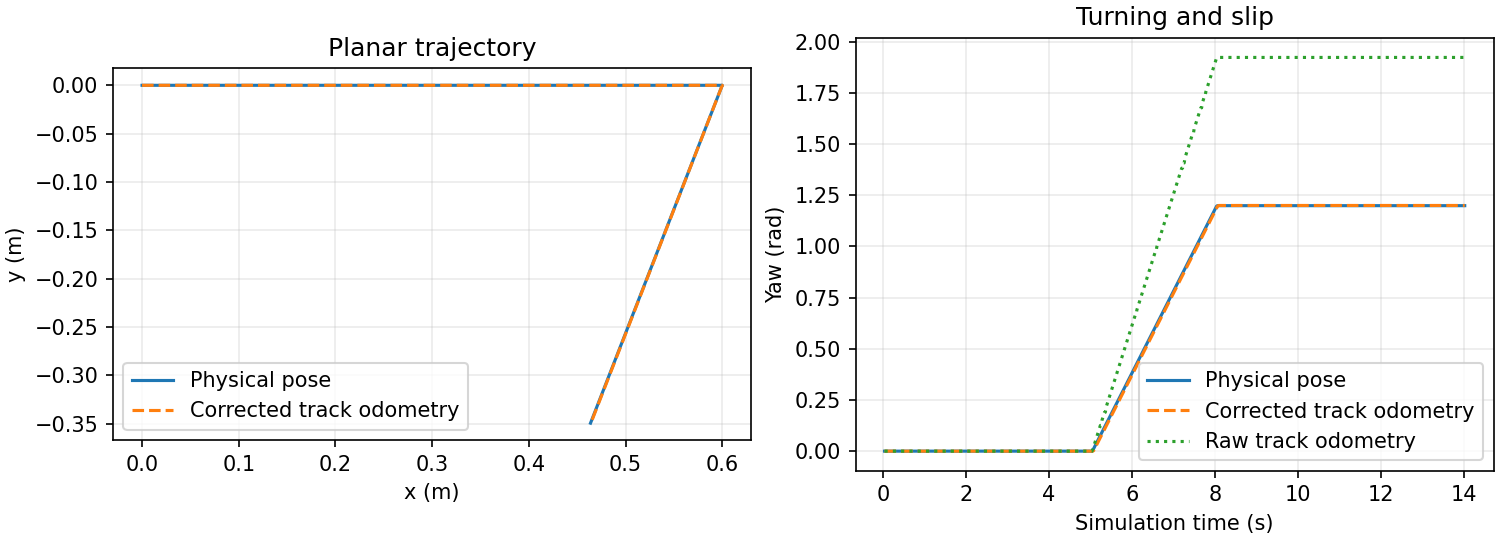

Saved physical-pose samples: 701
Last simulation timestamp (s): 14.02


In [3]:
display(Markdown('**Verification status: '+verification['status']+'**'))
show(['Verification', 'Passed'], list(verification['checks'].items()))
display(Image(filename=str(run/'trajectory.png')))
with (run/'trajectory.csv').open(encoding='utf-8') as stream:
    trajectory = list(csv.DictReader(stream))
print('Saved physical-pose samples:', len(trajectory))
print('Last simulation timestamp (s):', trajectory[-1]['time_s'])

## 3. Record integrity

Verify the saved artifacts using SHA-256. Report source-code consistency separately.

In [4]:
artifact_matches = {name: hashlib.sha256((run/name).read_bytes()).hexdigest()==digest
    for name, digest in manifest['artifact_sha256'].items()}
assert all(artifact_matches.values()), 'Saved artifact changed'
source_matches = {name: (root/name).exists() and
    hashlib.sha256((root/name).read_bytes()).hexdigest()==digest
    for name, digest in manifest['source_sha256'].items()}
show(['Integrity check', 'Result'], [['Captured artifacts match', all(artifact_matches.values())],
    ['Current source matches captured source', all(source_matches.values())]])

| Integrity check | Result |
|---|---|
| Captured artifacts match | True |
| Current source matches captured source | True |

## Steering correction and independent checks

| Item | Original | Corrected |
|---|---|---|
| Target rotation (rad) | 1.200000 | 1.200000 |
| Physical rotation (rad) | 0.745663 | 1.188290 |
| Relative turn error (%) | 37.86 | 0.98 |

The original fixture used steering efficiency 1.0. The measured steady track-to-body yaw gain was approximately 0.62370 in both +/-0.4 rad/s calibration turns. The frozen efficiency and odometry yaw scale are now **0.624** in [drive.json](testing_code/src/well_e_bunker_sim/config/drive.json).

The [diagnostic run](result/run_20261027T220231_218839Z/metrics.json) retains the original and compensated left/right turns and arcs. Parameters were fitted from its two efficiency=1 in-place cases. The following validation uses different turn rates (+/-0.2 and +/-0.6 rad/s) and wider arcs (0.2 m/s, +/-0.2 rad/s), without retuning:

| Validation case | Target (rad) | Physical (rad) | Turn error (%) | Odom yaw error (rad) | Passed |
|---|---|---|---|---|---|
| slow_left | 0.5000 | 0.4941 | 1.18 | 0.0013 | True |
| slow_right | -0.5000 | -0.4941 | 1.18 | 0.0013 | True |
| fast_left | 1.2000 | 1.1807 | 1.61 | 0.0023 | True |
| fast_right | -1.2000 | -1.1807 | 1.61 | 0.0023 | True |
| wide_arc_left | 0.6004 | 0.6096 | 1.54 | 0.0168 | True |
| wide_arc_right | -0.6000 | -0.6096 | 1.61 | 0.0168 | True |

Validation status: **passed**. Limits were set before execution: turn error <10%, odometry yaw error <0.05 rad and accumulated planar odometry error <0.05 m. Maximum planar error was 0.0345 m. Evidence: [validation metrics](result/run_20261027T220604_865829Z/metrics.json) and [run manifest](result/run_20261027T220604_865829Z/manifest.json).

The default smoke test is also stricter: its former 0.4-1.8 rad turning check is replaced by <5% error from 1.2 rad and <0.05 rad odometry turn error. Earlier result files are preserved.

Public `/odom` and `odom → base_link` now come from [odometry_adapter.py](testing_code/src/well_e_bunker_sim/scripts/odometry_adapter.py), which integrates raw track velocity with the calibrated yaw scale. It does **not** subscribe to simulator ground truth. Raw odometry/TF remain on `/simulation/track_odom` and `/simulation/track_tf`; the independent body pose remains available for evaluation only. Odometry covariance is not calibrated.

The correction is specific to this flat-ground simulated contact model. It is not a real Bunker Mini calibration or evidence for other terrain. The upstream [TrackedVehicle implementation](https://github.com/gazebosim/gz-sim/blob/gz-sim8/src/systems/tracked_vehicle/TrackedVehicle.cc) applies steering efficiency to track commands but integrates uncorrected virtual-wheel odometry; this is why adjusting the drive parameter alone is insufficient.

In [5]:
calibration_run = root/'result'/'run_20261027T220231_218839Z'
validation_run = root/'result'/'run_20261027T220604_865829Z'
calibration = read(calibration_run/'metrics.json')
validation = read(validation_run/'metrics.json')
assert calibration['status'] == 'passed'
assert validation['status'] == 'passed'
assert len(validation['cases']) == 6
assert all(case['passed'] for case in validation['cases'])
for evidence in [calibration_run, validation_run]:
    record = read(evidence/'manifest.json')
    assert all(hashlib.sha256((evidence/name).read_bytes()).hexdigest()==digest
        for name, digest in record['artifact_sha256'].items())
print('Calibration and independent validation artifacts verified.')

Calibration and independent validation artifacts verified.


## 4. Conclusions and next stage

Basic motion, command-timeout stopping and odom/TF checks passed. Flat-ground steering compensation and corrected odometry passed the stricter smoke test and six additional maneuvers. This is simulation calibration only; covariance and hardware dynamics remain uncalibrated. Navigation is evaluated separately in [Nav2_test](../Nav2_test/README.md); GP/GRG ROS integration remains pending.

See the [README](README.md) and [smoke_test.py](testing_code/src/well_e_bunker_sim/scripts/smoke_test.py) for execution instructions and acceptance thresholds.